In [1]:
!pip install -q kagglehub shap xgboost openpyxl seaborn

In [2]:
import os
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import kagglehub

from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve,
    auc
)

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

In [3]:
path = kagglehub.dataset_download(
    "ankitverma2010/ecommerce-customer-churn-analysis-and-prediction"
)

files = glob.glob(
    os.path.join(path, "**", "*.xlsx"),
    recursive=True
)

if not files:
    raise FileNotFoundError("Excel dataset not found.")

df = pd.read_excel(
    files[0],
    sheet_name="E Comm"
)

print("Dataset shape:", df.shape)
display(df.head())

Using Colab cache for faster access to the 'ecommerce-customer-churn-analysis-and-prediction' dataset.
Dataset shape: (5630, 20)


,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93
1,50002,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,120.90
2,50003,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120.28
3,50004,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134.07
4,50005,1,0.0,Phone,1,12.0,CC,Male,NaN,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,129.60


In [4]:
print("Dataset Information:")
df.info()

print("\nDataset Dimensions:")
print(df.shape)

print("\nMissing Values:")
display(
    df.isnull().sum().sort_values(ascending=False)
)

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nChurn Distribution:")
display(df["Churn"].value_counts())

print("\nChurn Percentage:")
display(
    (df["Churn"].value_counts(normalize=True) * 100).round(2)
)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5630 entries, 0 to 5629
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   CustomerID                   5630 non-null   int64  
 1   Churn                        5630 non-null   int64  
 2   Tenure                       5366 non-null   float64
 3   PreferredLoginDevice         5630 non-null   object 
 4   CityTier                     5630 non-null   int64  
 5   WarehouseToHome              5379 non-null   float64
 6   PreferredPaymentMode         5630 non-null   object 
 7   Gender                       5630 non-null   object 
 8   HourSpendOnApp               5375 non-null   float64
 9   NumberOfDeviceRegistered     5630 non-null   int64  
 10  PreferedOrderCat             5630 non-null   object 
 11  SatisfactionScore            5630 non-null   int64  
 12  MaritalStatus                5630 non-null   object 
 1

,0
DaySinceLastOrder,307
OrderAmountHikeFromlastYear,265
Tenure,264
OrderCount,258
CouponUsed,256
HourSpendOnApp,255
WarehouseToHome,251
CustomerID,0
PreferredLoginDevice,0
Churn,0



Duplicate Rows:
0

Churn Distribution:


,count
Churn,
0,4682
1,948



Churn Percentage:


,proportion
Churn,
0,83.16
1,16.84


In [5]:
df = df.copy()

# Remove rows without target labels
df = df.dropna(subset=["Churn"])

# Standardize selected category names
category_maps = {
    "PreferredLoginDevice": {
        "Phone": "Mobile Phone"
    },
    "PreferredPaymentMode": {
        "CC": "Credit Card",
        "COD": "Cash on Delivery"
    },
    "PreferedOrderCat": {
        "Mobile": "Mobile Phone"
    }
}

for col, mapping in category_maps.items():
    if col in df.columns:
        df[col] = df[col].replace(mapping)

print("Data cleaning completed.")

print("\nMissing Values:")
display(df.isnull().sum()[df.isnull().sum() > 0])

print("\nDataset shape:", df.shape)

Data cleaning completed.

Missing Values:


,0
Tenure,264
WarehouseToHome,251
HourSpendOnApp,255
OrderAmountHikeFromlastYear,265
CouponUsed,256
OrderCount,258
DaySinceLastOrder,307



Dataset shape: (5630, 20)


In [6]:
# EDA

Overall Churn Rate: 16.84%


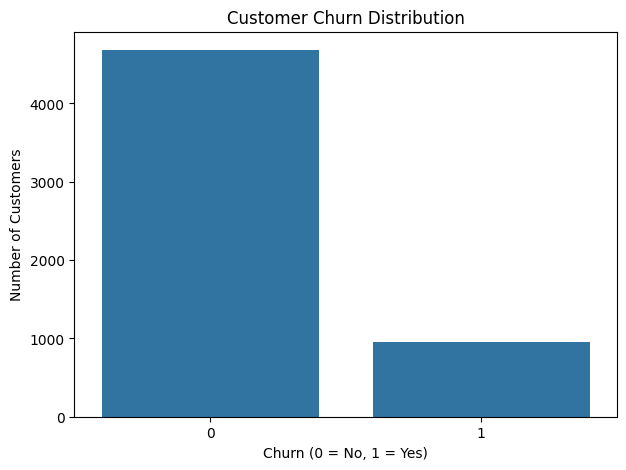

In [7]:
churn_rate = df["Churn"].mean()

print(f"Overall Churn Rate: {churn_rate:.2%}")

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Churn"
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.show()

In [8]:
categorical_analysis = [
    "Complain",
    "SatisfactionScore",
    "CityTier",
    "PreferedOrderCat",
    "PreferredPaymentMode",
    "MaritalStatus",
    "NumberOfDeviceRegistered"
]

for col in categorical_analysis:

    if col not in df.columns:
        continue

    print(f"\nChurn Rate by {col}")

    result = df.groupby(
        col,
        observed=False
    )["Churn"].agg(["mean", "count"])

    result["Churn Percentage"] = result["mean"] * 100

    display(result.round(3))


Churn Rate by Complain


,mean,count,Churn Percentage
Complain,,,
0,0.109,4026,10.929
1,0.317,1604,31.671



Churn Rate by SatisfactionScore


,mean,count,Churn Percentage
SatisfactionScore,,,
1,0.115,1164,11.512
2,0.126,586,12.628
3,0.172,1698,17.197
4,0.171,1074,17.132
5,0.238,1108,23.827



Churn Rate by CityTier


,mean,count,Churn Percentage
CityTier,,,
1,0.145,3666,14.512
2,0.198,242,19.835
3,0.214,1722,21.370


... (4 outputs left out)


Churn Rate by MaritalStatus


,mean,count,Churn Percentage
MaritalStatus,,,
Divorced,0.146,848,14.623
Married,0.115,2986,11.520
Single,0.267,1796,26.726



Churn Rate by NumberOfDeviceRegistered


,mean,count,Churn Percentage
NumberOfDeviceRegistered,,,
1,0.094,235,9.362
2,0.094,276,9.420
3,0.149,1699,14.950
4,0.165,2377,16.491
5,0.225,881,22.474
6,0.346,162,34.568


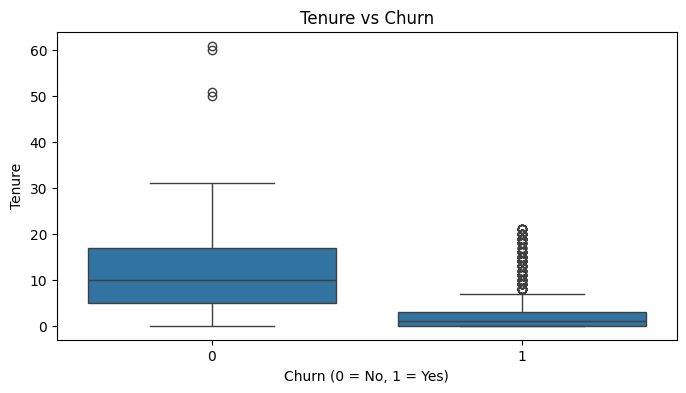

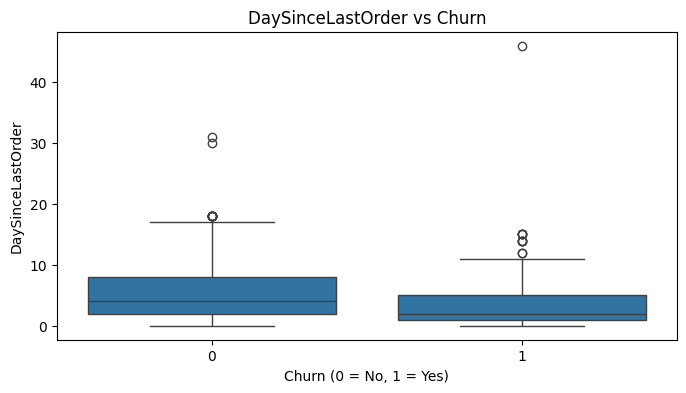

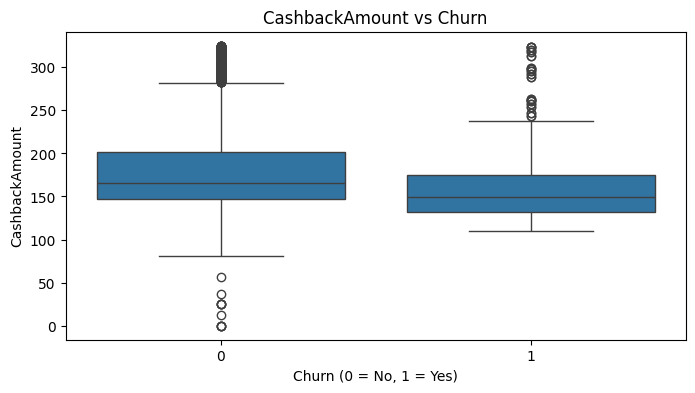

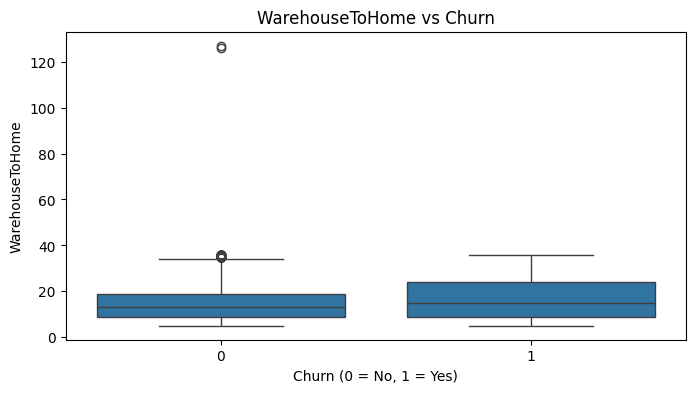

In [9]:
numeric_analysis = [
    "Tenure",
    "DaySinceLastOrder",
    "CashbackAmount",
    "WarehouseToHome"
]

for col in numeric_analysis:

    if col not in df.columns:
        continue

    plt.figure(figsize=(8, 4))

    sns.boxplot(
        data=df,
        x="Churn",
        y=col
    )

    plt.title(f"{col} vs Churn")
    plt.xlabel("Churn (0 = No, 1 = Yes)")
    plt.ylabel(col)

    plt.show()

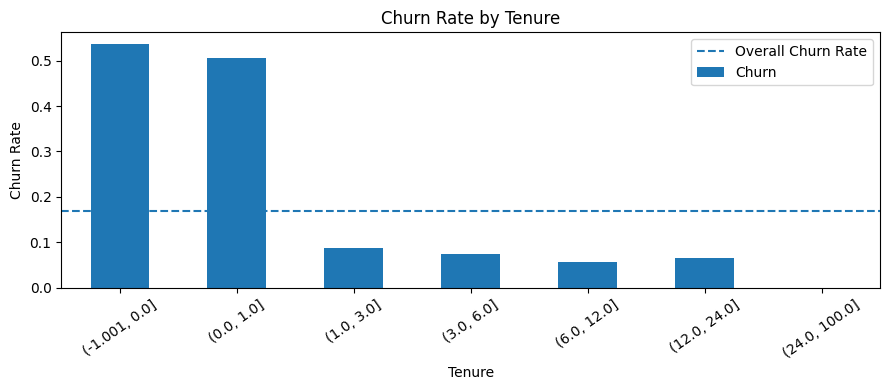

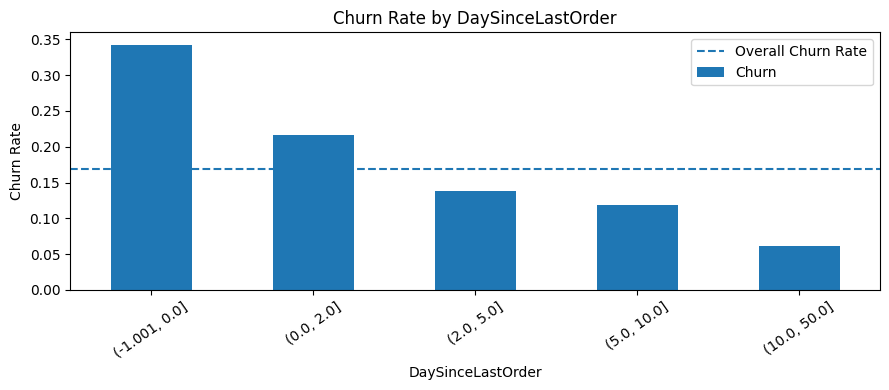

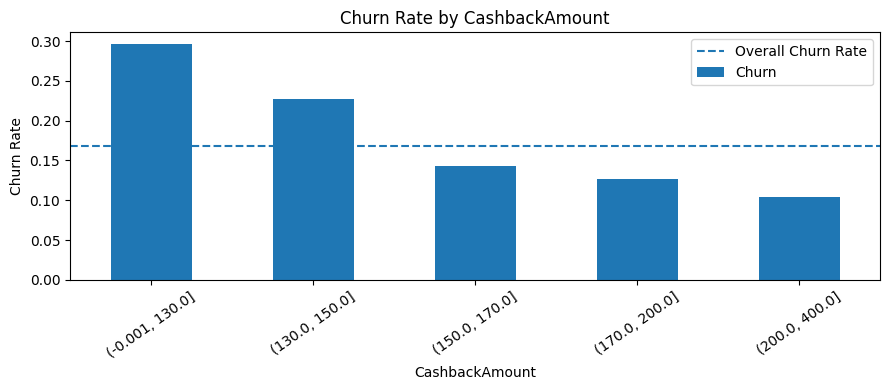

In [10]:
bins = {
    "Tenure": [-1, 0, 1, 3, 6, 12, 24, 100],
    "DaySinceLastOrder": [-1, 0, 2, 5, 10, 50],
    "CashbackAmount": [0, 130, 150, 170, 200, 400]
}

for col, edges in bins.items():

    if col not in df.columns:
        continue

    temp = df.copy()

    temp["Group"] = pd.cut(
        temp[col],
        bins=edges,
        include_lowest=True
    )

    churn_by_group = temp.groupby(
        "Group",
        observed=False
    )["Churn"].mean()

    plt.figure(figsize=(9, 4))

    churn_by_group.plot(kind="bar")

    plt.axhline(
        churn_rate,
        linestyle="--",
        label="Overall Churn Rate"
    )

    plt.title(f"Churn Rate by {col}")
    plt.ylabel("Churn Rate")
    plt.xlabel(col)
    plt.legend()
    plt.xticks(rotation=35)
    plt.tight_layout()
    plt.show()

In [11]:
# Target
y = df["Churn"].astype(int)

# Exclude ID and target
X = df.drop(
    columns=["CustomerID", "Churn"],
    errors="ignore"
).copy()

# Create groups based on identical feature records
groups = pd.util.hash_pandas_object(
    X,
    index=False
).to_numpy()

# Stratified group split: 80% train, 20% test
splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

groups_train = groups[train_idx]

print("Training data:", X_train.shape)
print("Test data:", X_test.shape)

print("\nTraining churn rate:", round(y_train.mean(), 3))
print("Test churn rate:", round(y_test.mean(), 3))

print("\nTraining class distribution:")
display(y_train.value_counts())

print("\nTest class distribution:")
display(y_test.value_counts())

Training data: (4508, 18)
Test data: (1122, 18)

Training churn rate: 0.17
Test churn rate: 0.162

Training class distribution:


,count
Churn,
0,3742
1,766



Test class distribution:


,count
Churn,
0,940
1,182


In [12]:
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['Tenure', 'CityTier', 'WarehouseToHome', 'HourSpendOnApp', 'NumberOfDeviceRegistered', 'SatisfactionScore', 'NumberOfAddress', 'Complain', 'OrderAmountHikeFromlastYear', 'CouponUsed', 'OrderCount', 'DaySinceLastOrder', 'CashbackAmount']
Categorical features: ['PreferredLoginDevice', 'PreferredPaymentMode', 'Gender', 'PreferedOrderCat', 'MaritalStatus']


In [13]:
# Class imbalance ratio
spw = (
    (y_train == 0).sum() /
    (y_train == 1).sum()
)

models = {
    "Logistic Regression": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", LogisticRegression(
            max_iter=3000,
            class_weight="balanced"
        ))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", RandomForestClassifier(
            n_estimators=400,
            min_samples_leaf=2,
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "XGBoost": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", XGBClassifier(
            n_estimators=400,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            scale_pos_weight=spw,
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        ))
    ])
}

print("Models created successfully.")

Models created successfully.


In [14]:
cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

cv_rows = []

for name, model in models.items():

    print(f"Evaluating: {name}")

    scores = cross_validate(
        model,
        X_train,
        y_train,
        groups=groups_train,
        cv=cv,
        scoring=scoring,
        n_jobs=1
    )

    cv_rows.append({
        "Model": name,
        "Accuracy Mean": scores["test_accuracy"].mean(),
        "Accuracy Std": scores["test_accuracy"].std(),
        "Precision Mean": scores["test_precision"].mean(),
        "Recall Mean": scores["test_recall"].mean(),
        "F1 Mean": scores["test_f1"].mean(),
        "ROC-AUC Mean": scores["test_roc_auc"].mean(),
        "PR-AUC Mean": scores["test_pr_auc"].mean()
    })

cv_results = pd.DataFrame(cv_rows)

print("\nCross Validation Results:")
display(cv_results.round(3))

Evaluating: Logistic Regression
Evaluating: Random Forest
Evaluating: XGBoost

Cross Validation Results:


,Model,Accuracy Mean,Accuracy Std,Precision Mean,Recall Mean,F1 Mean,ROC-AUC Mean,PR-AUC Mean
0,Logistic Regression,0.800,0.017,0.449,0.800,0.575,0.884,0.687
1,Random Forest,0.930,0.012,0.838,0.722,0.775,0.971,0.882
2,XGBoost,0.924,0.013,0.741,0.838,0.786,0.961,0.856


In [15]:
for name, model in models.items():

    print(f"Training: {name}")

    model.fit(X_train, y_train)

# Calculate churn probabilities
probs = {}

for name, model in models.items():

    probs[name] = model.predict_proba(X_test)[:, 1]

print("\nAll models trained successfully.")

Training: Logistic Regression
Training: Random Forest
Training: XGBoost

All models trained successfully.


In [16]:
metric_rows = []

for name, p in probs.items():

    pred = (p >= 0.5).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        pred,
        labels=[0, 1]
    ).ravel()

    accuracy = accuracy_score(y_test, pred)

    error_rate = 1 - accuracy

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0 else 0
    )

    fpr = (
        fp / (fp + tn)
        if (fp + tn) > 0 else 0
    )

    fnr = (
        fn / (fn + tp)
        if (fn + tp) > 0 else 0
    )

    metric_rows.append({
        "Model": name,
        "Accuracy": accuracy,
        "Error Rate": error_rate,
        "Balanced Accuracy": balanced_accuracy_score(
            y_test, pred
        ),
        "Precision": precision_score(
            y_test, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred, zero_division=0
        ),
        "Specificity": specificity,
        "F1 Score": f1_score(
            y_test, pred, zero_division=0
        ),
        "False Positive Rate": fpr,
        "False Negative Rate": fnr,
        "ROC-AUC": roc_auc_score(y_test, p),
        "PR-AUC": average_precision_score(y_test, p)
    })

error_results = pd.DataFrame(metric_rows)

display(error_results.round(3))

,Model,Accuracy,Error Rate,Balanced Accuracy,Precision,Recall,Specificity,F1 Score,False Positive Rate,False Negative Rate,ROC-AUC,PR-AUC
0,Logistic Regression,0.819,0.181,0.821,0.467,0.824,0.818,0.596,0.182,0.176,0.903,0.734
1,Random Forest,0.950,0.050,0.879,0.904,0.775,0.984,0.834,0.016,0.225,0.985,0.941
2,XGBoost,0.938,0.062,0.925,0.757,0.907,0.944,0.825,0.056,0.093,0.980,0.915


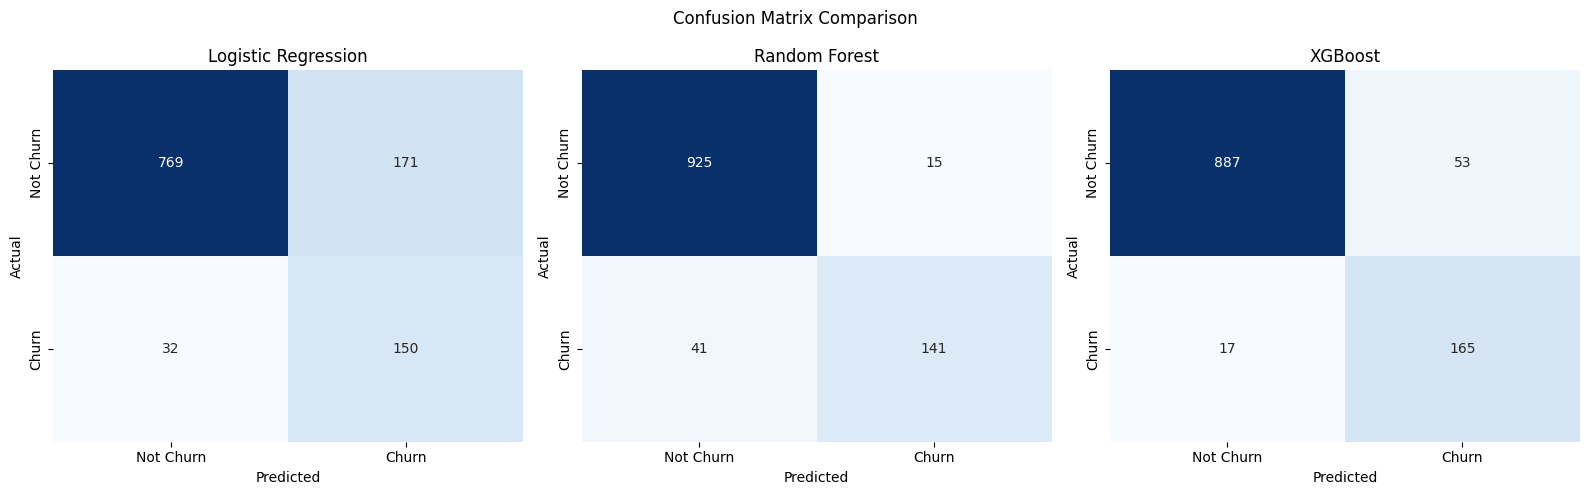

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, p) in zip(axes, probs.items()):

    pred = (p >= 0.5).astype(int)

    cm = confusion_matrix(
        y_test,
        pred,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Not Churn", "Churn"],
        yticklabels=["Not Churn", "Churn"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.suptitle("Confusion Matrix Comparison")
plt.tight_layout()
plt.show()

In [18]:
for name, p in probs.items():

    pred = (p >= 0.5).astype(int)

    print("\n", "=" * 45)
    print(name)
    print("=" * 45)

    print(
        classification_report(
            y_test,
            pred,
            target_names=["Not Churn", "Churn"],
            zero_division=0
        )
    )


Logistic Regression
              precision    recall  f1-score   support

   Not Churn       0.96      0.82      0.88       940
       Churn       0.47      0.82      0.60       182

    accuracy                           0.82      1122
   macro avg       0.71      0.82      0.74      1122
weighted avg       0.88      0.82      0.84      1122


Random Forest
              precision    recall  f1-score   support

   Not Churn       0.96      0.98      0.97       940
       Churn       0.90      0.77      0.83       182

    accuracy                           0.95      1122
   macro avg       0.93      0.88      0.90      1122
weighted avg       0.95      0.95      0.95      1122


XGBoost
              precision    recall  f1-score   support

   Not Churn       0.98      0.94      0.96       940
       Churn       0.76      0.91      0.82       182

    accuracy                           0.94      1122
   macro avg       0.87      0.93      0.89      1122
weighted avg       0.94      

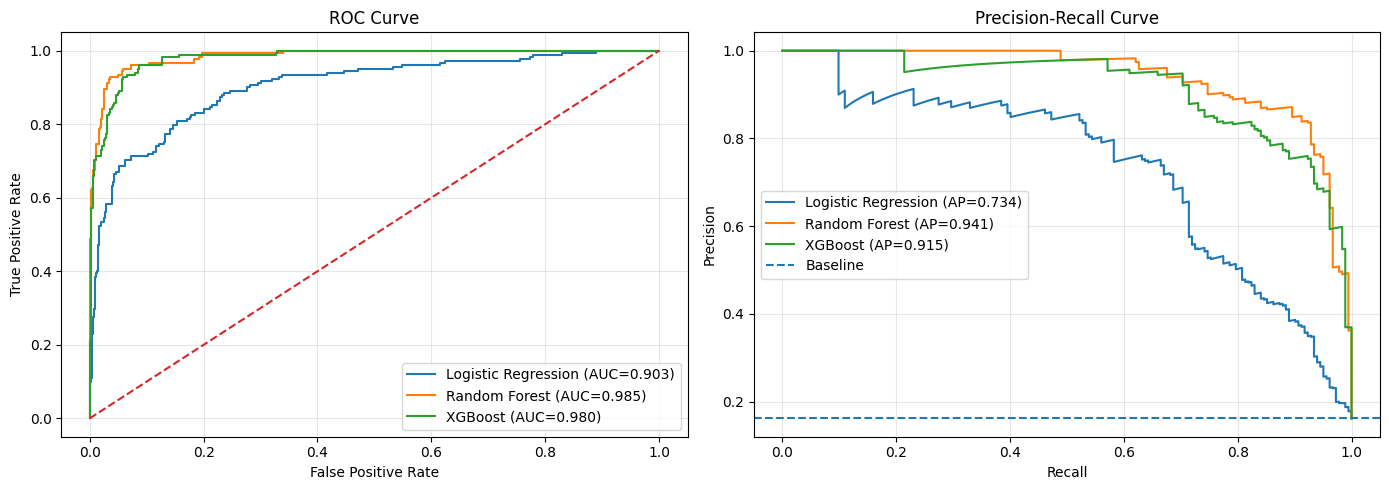

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ROC Curve
for name, p in probs.items():

    fpr, tpr, thresholds = roc_curve(y_test, p)

    roc_auc = auc(fpr, tpr)

    axes[0].plot(
        fpr,
        tpr,
        label=f"{name} (AUC={roc_auc:.3f})"
    )

axes[0].plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

axes[0].set_title("ROC Curve")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Precision-Recall Curve
for name, p in probs.items():

    precision, recall, thresholds = precision_recall_curve(
        y_test,
        p
    )

    ap = average_precision_score(y_test, p)

    axes[1].plot(
        recall,
        precision,
        label=f"{name} (AP={ap:.3f})"
    )

axes[1].axhline(
    y_test.mean(),
    linestyle="--",
    label="Baseline"
)

axes[1].set_title("Precision-Recall Curve")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [20]:
threshold_rows = []

for name, p in probs.items():

    for threshold in [0.2, 0.3, 0.4, 0.5, 0.6]:

        pred = (p >= threshold).astype(int)

        threshold_rows.append({
            "Model": name,
            "Threshold": threshold,
            "Precision": precision_score(
                y_test, pred, zero_division=0
            ),
            "Recall": recall_score(
                y_test, pred, zero_division=0
            ),
            "F1 Score": f1_score(
                y_test, pred, zero_division=0
            ),
            "Predicted Churn Customers": pred.sum()
        })

threshold_results = pd.DataFrame(threshold_rows)

display(threshold_results.round(3))

,Model,Threshold,Precision,Recall,F1 Score,Predicted Churn Customers
0,Logistic Regression,0.2,0.274,0.951,0.425,632
1,Logistic Regression,0.3,0.347,0.934,0.506,490
2,Logistic Regression,0.4,0.400,0.890,0.552,405
3,Logistic Regression,0.5,0.467,0.824,0.596,321
4,Logistic Regression,0.6,0.529,0.764,0.625,263
5,Random Forest,0.2,0.573,0.967,0.720,307
6,Random Forest,0.3,0.703,0.962,0.812,249
7,Random Forest,0.4,0.840,0.923,0.880,200
8,Random Forest,0.5,0.904,0.775,0.834,156
9,Random Forest,0.6,0.960,0.654,0.778,124


In [21]:
risk_rows = []

for name, p in probs.items():

    risk_df = pd.DataFrame({
        "Actual": y_test.to_numpy(),
        "Churn_Probability": p
    })

    risk_df = risk_df.sort_values(
        "Churn_Probability",
        ascending=False
    )

    k = int(np.ceil(len(risk_df) * 0.10))

    top_10 = risk_df.head(k)

    churn_capture = (
        top_10["Actual"].sum() /
        risk_df["Actual"].sum()
        if risk_df["Actual"].sum() > 0 else 0
    )

    risk_rows.append({
        "Model": name,
        "Top 10% Churn Rate": top_10["Actual"].mean(),
        "Churn Capture Rate": churn_capture,
        "Lift": (
            top_10["Actual"].mean() / y_test.mean()
            if y_test.mean() > 0 else 0
        ),
        "Selected Customers": k
    })

risk_results = pd.DataFrame(risk_rows)

display(risk_results.round(3))

,Model,Top 10% Churn Rate,Churn Capture Rate,Lift,Selected Customers
0,Logistic Regression,0.841,0.522,5.183,113
1,Random Forest,0.982,0.610,6.056,113
2,XGBoost,0.956,0.593,5.892,113


In [22]:
# Sample the test data
X_shap = X_test.sample(
    n=min(500, len(X_test)),
    random_state=42
)

def calculate_shap(model_pipeline, data):

    fitted_preprocessor = model_pipeline.named_steps[
        "preprocessor"
    ]

    classifier = model_pipeline.named_steps[
        "classifier"
    ]

    transformed_data = fitted_preprocessor.transform(data)

    if hasattr(transformed_data, "toarray"):
        transformed_data = transformed_data.toarray()

    feature_names = (
        fitted_preprocessor.get_feature_names_out()
    )

    explainer = shap.TreeExplainer(classifier)

    values = explainer.shap_values(transformed_data)

    if isinstance(values, list):
        values = values[1]

    values = np.asarray(values)

    if values.ndim == 3:
        values = values[:, :, 1]

    return values, transformed_data, feature_names


shap_rf, X_rf_transformed, feature_names_rf = calculate_shap(
    models["Random Forest"],
    X_shap
)

shap_xgb, X_xgb_transformed, feature_names_xgb = calculate_shap(
    models["XGBoost"],
    X_shap
)

print("SHAP values calculated successfully.")

SHAP values calculated successfully.


In [23]:
importance_rf = pd.Series(
    np.abs(shap_rf).mean(axis=0),
    index=feature_names_rf,
    name="Random Forest"
)

importance_xgb = pd.Series(
    np.abs(shap_xgb).mean(axis=0),
    index=feature_names_xgb,
    name="XGBoost"
)

shap_comparison = pd.concat(
    [importance_rf, importance_xgb],
    axis=1
).fillna(0)

# Relative importance percentages
shap_percentage = shap_comparison.div(
    shap_comparison.sum(axis=0),
    axis=1
) * 100

shap_percentage = shap_percentage.sort_values(
    "Random Forest",
    ascending=False
)

print("TOP 15 FEATURES")
display(shap_percentage.head(15).round(2))

TOP 15 FEATURES


,Random Forest,XGBoost
num__Tenure,26.83,25.20
num__Complain,12.61,10.30
num__CashbackAmount,5.73,7.23
cat__PreferedOrderCat_Mobile Phone,5.62,1.64
num__DaySinceLastOrder,5.50,5.08
num__NumberOfAddress,4.89,7.91
cat__MaritalStatus_Single,4.21,4.24
num__CityTier,4.03,4.55
num__SatisfactionScore,3.54,4.28
num__WarehouseToHome,3.53,4.14


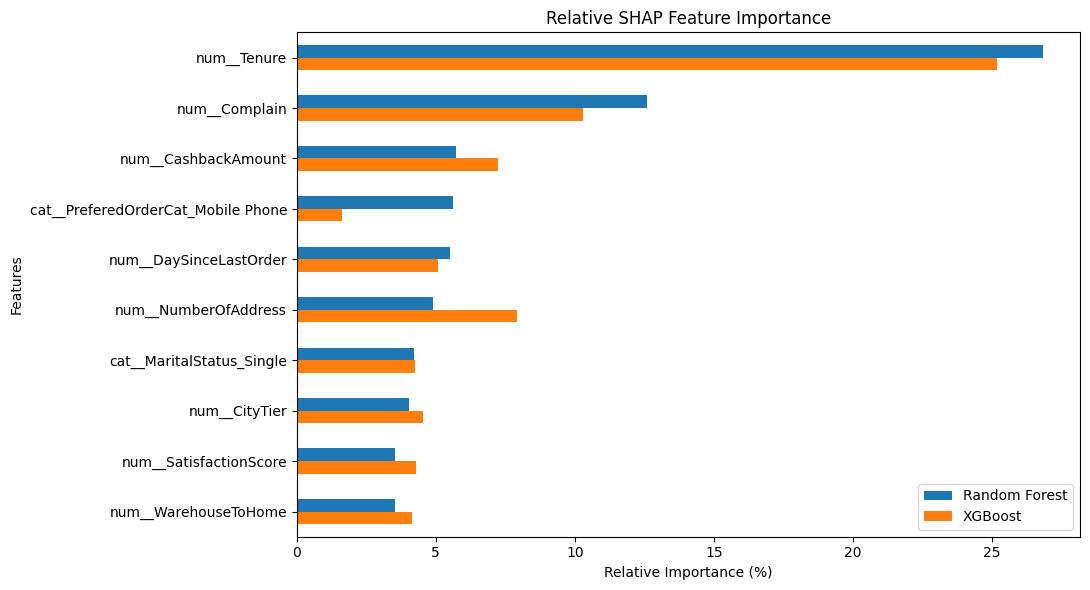

In [24]:
#Graphs
top_features = (
    shap_percentage
    .head(10)
    .index
)

shap_percentage.loc[
    top_features,
    ["Random Forest", "XGBoost"]
].plot(
    kind="barh",
    figsize=(11, 6)
)

plt.title("Relative SHAP Feature Importance")
plt.xlabel("Relative Importance (%)")
plt.ylabel("Features")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


Random Forest SHAP Analysis


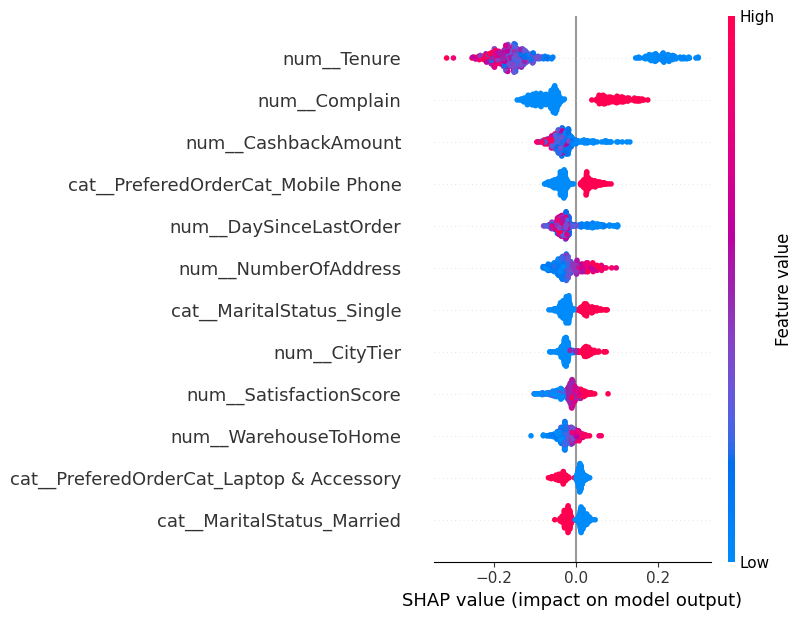

XGBoost SHAP Analysis


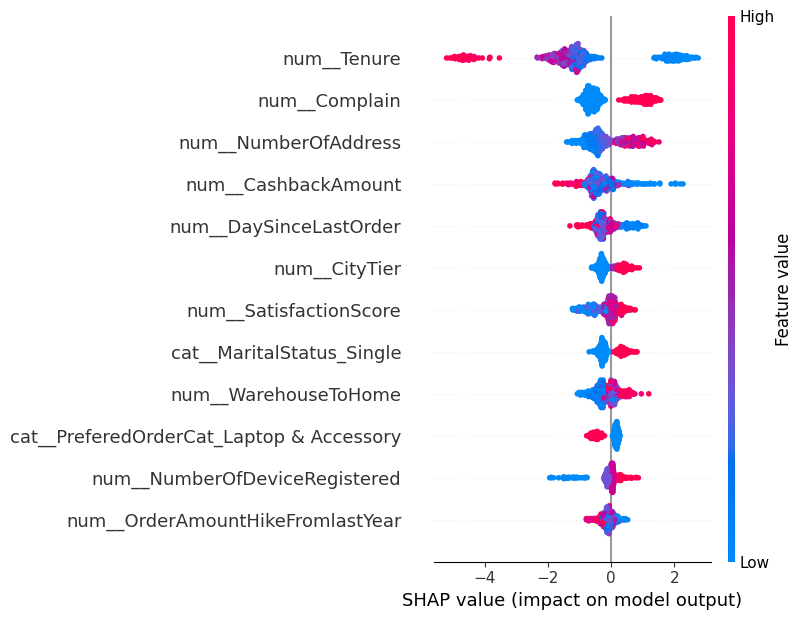

In [25]:
print("Random Forest SHAP Analysis")

shap.summary_plot(
    shap_rf,
    X_rf_transformed,
    feature_names=feature_names_rf,
    max_display=12
)

print("XGBoost SHAP Analysis")

shap.summary_plot(
    shap_xgb,
    X_xgb_transformed,
    feature_names=feature_names_xgb,
    max_display=12
)

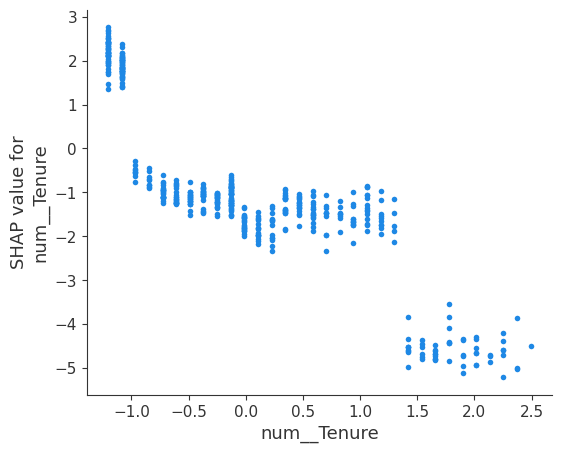

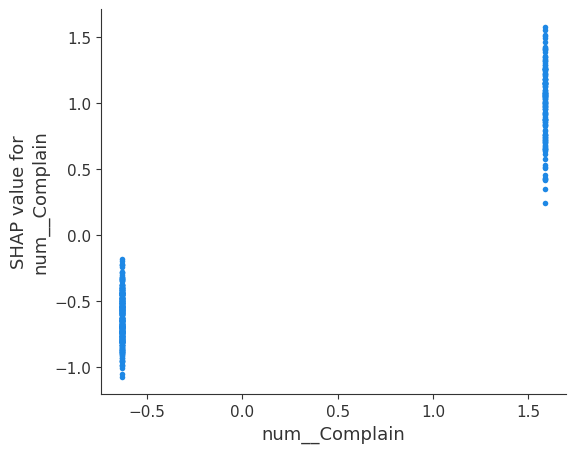

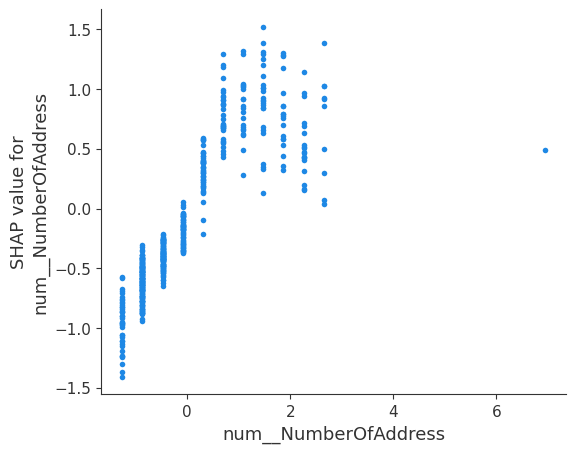

In [26]:
top_3_features = (
    importance_xgb
    .sort_values(ascending=False)
    .head(3)
    .index.tolist()
)

for feature in top_3_features:

    feature_index = list(feature_names_xgb).index(feature)

    shap.dependence_plot(
        feature_index,
        shap_xgb,
        X_xgb_transformed,
        feature_names=feature_names_xgb,
        interaction_index=None
    )

In [27]:
business_features = [
    "Tenure",
    "Complain",
    "NumberOfAddress",
    "CashbackAmount",
    "DaySinceLastOrder",
    "SatisfactionScore",
    "PreferedOrderCat"
]

for feature in business_features:

    if feature not in df.columns:
        continue

    print("\n" + "=" * 50)
    print("Feature:", feature)
    print("=" * 50)

    if df[feature].nunique() <= 10:

        result = df.groupby(
            feature,
            observed=False
        )["Churn"].agg(["mean", "count"])

    else:

        temp = df[[feature, "Churn"]].copy()

        temp["Group"] = pd.qcut(
            temp[feature],
            q=5,
            duplicates="drop"
        )

        result = temp.groupby(
            "Group",
            observed=False
        )["Churn"].agg(["mean", "count"])

    result["Churn Percentage"] = result["mean"] * 100

    display(result.round(3))


Feature: Tenure


,mean,count,Churn Percentage
Group,,,
"(-0.001, 1.0]",0.518,1198,51.836
"(1.0, 6.0]",0.080,952,7.983
"(6.0, 11.0]",0.060,1138,5.975
"(11.0, 18.0]",0.059,1076,5.948
"(18.0, 61.0]",0.038,1002,3.792



Feature: Complain


,mean,count,Churn Percentage
Complain,,,
0,0.109,4026,10.929
1,0.317,1604,31.671



Feature: NumberOfAddress


,mean,count,Churn Percentage
Group,,,
"(0.999, 2.0]",0.164,1740,16.437
"(2.0, 3.0]",0.178,1278,17.840
"(3.0, 4.0]",0.111,588,11.054
"(4.0, 6.0]",0.140,953,13.956
"(6.0, 22.0]",0.220,1071,22.035


... (4 outputs left out)


Feature: SatisfactionScore


,mean,count,Churn Percentage
SatisfactionScore,,,
1,0.115,1164,11.512
2,0.126,586,12.628
3,0.172,1698,17.197
4,0.171,1074,17.132
5,0.238,1108,23.827



Feature: PreferedOrderCat


,mean,count,Churn Percentage
PreferedOrderCat,,,
Fashion,0.155,826,15.496
Grocery,0.049,410,4.878
Laptop & Accessory,0.102,2050,10.244
Mobile Phone,0.274,2080,27.404
Others,0.076,264,7.576


In [28]:
final_results = error_results.merge(
    cv_results,
    on="Model",
    how="left"
)

final_results = final_results.merge(
    risk_results,
    on="Model",
    how="left"
)

print("FINAL MODEL COMPARISON")

display(final_results.round(3))

# Best model by F1
best_f1_model = error_results.loc[
    error_results["F1 Score"].idxmax()
]

# Best model by Recall
best_recall_model = error_results.loc[
    error_results["Recall"].idxmax()
]

# Best model by ROC-AUC
best_roc_model = error_results.loc[
    error_results["ROC-AUC"].idxmax()
]

# Best model by cross-validation F1
best_cv_model = cv_results.loc[
    cv_results["F1 Mean"].idxmax()
]

print("\nFINAL FINDINGS")
print("-" * 45)

print(
    f"Best F1 Model: {best_f1_model['Model']} "
    f"({best_f1_model['F1 Score']:.3f})"
)

print(
    f"Best Recall Model: {best_recall_model['Model']} "
    f"({best_recall_model['Recall']:.3f})"
)

print(
    f"Best ROC-AUC Model: {best_roc_model['Model']} "
    f"({best_roc_model['ROC-AUC']:.3f})"
)

print(
    f"Best CV F1 Model: {best_cv_model['Model']} "
    f"({best_cv_model['F1 Mean']:.3f})"
)

FINAL MODEL COMPARISON


,Model,Accuracy,Error Rate,Balanced Accuracy,Precision,Recall,Specificity,F1 Score,False Positive Rate,False Negative Rate,ROC-AUC,PR-AUC,Accuracy Mean,Accuracy Std,Precision Mean,Recall Mean,F1 Mean,ROC-AUC Mean,PR-AUC Mean,Top 10% Churn Rate,Churn Capture Rate,Lift,Selected Customers
0,Logistic Regression,0.819,0.181,0.821,0.467,0.824,0.818,0.596,0.182,0.176,0.903,0.734,0.800,0.017,0.449,0.800,0.575,0.884,0.687,0.841,0.522,5.183,113
1,Random Forest,0.950,0.050,0.879,0.904,0.775,0.984,0.834,0.016,0.225,0.985,0.941,0.930,0.012,0.838,0.722,0.775,0.971,0.882,0.982,0.610,6.056,113
2,XGBoost,0.938,0.062,0.925,0.757,0.907,0.944,0.825,0.056,0.093,0.980,0.915,0.924,0.013,0.741,0.838,0.786,0.961,0.856,0.956,0.593,5.892,113



FINAL FINDINGS
---------------------------------------------
Best F1 Model: Random Forest (0.834)
Best Recall Model: XGBoost (0.907)
Best ROC-AUC Model: Random Forest (0.985)
Best CV F1 Model: XGBoost (0.786)


In [29]:
print("=" * 60)
print("CUSTOMER CHURN ANALYSIS - FINAL REPORT")
print("=" * 60)

print("\n1. MODEL PERFORMANCE")

for _, row in error_results.iterrows():

    print(f"\n{row['Model']}")
    print(f"Accuracy: {row['Accuracy']:.3f}")
    print(f"Error Rate: {row['Error Rate']:.3f}")
    print(f"Precision: {row['Precision']:.3f}")
    print(f"Recall: {row['Recall']:.3f}")
    print(f"F1 Score: {row['F1 Score']:.3f}")
    print(f"ROC-AUC: {row['ROC-AUC']:.3f}")

print("\n2. MODEL SELECTION")

print("Best F1 Model:", best_f1_model["Model"])
print("Best Recall Model:", best_recall_model["Model"])

print("\n3. CROSS VALIDATION")

display(cv_results.round(3))

print("\n4. TOP CHURN PREDICTION FEATURES")

display(shap_percentage.head(5).round(2))

print("\n5. BUSINESS IMPLICATIONS")

print("""
- Monitor customers with short tenure.
- Improve complaint management processes.
- Identify customers who have not ordered recently.
- Evaluate customer satisfaction and cashback strategies.
- Prioritize high-risk customers for retention campaigns.
""")

print("\n6. LIMITATIONS")

print("""
- Results depend on the dataset and selected features.
- Model performance may change with different data splits.
- SHAP importance indicates model contribution, not causation.
- The optimal classification threshold depends on business costs.
""")

print("=" * 60)
print("ANALYSIS COMPLETED")
print("=" * 60)

CUSTOMER CHURN ANALYSIS - FINAL REPORT

1. MODEL PERFORMANCE

Logistic Regression
Accuracy: 0.819
Error Rate: 0.181
Precision: 0.467
Recall: 0.824
F1 Score: 0.596
ROC-AUC: 0.903

Random Forest
Accuracy: 0.950
Error Rate: 0.050
Precision: 0.904
Recall: 0.775
F1 Score: 0.834
ROC-AUC: 0.985

XGBoost
Accuracy: 0.938
Error Rate: 0.062
Precision: 0.757
Recall: 0.907
F1 Score: 0.825
ROC-AUC: 0.980

2. MODEL SELECTION
Best F1 Model: Random Forest
Best Recall Model: XGBoost

3. CROSS VALIDATION


,Model,Accuracy Mean,Accuracy Std,Precision Mean,Recall Mean,F1 Mean,ROC-AUC Mean,PR-AUC Mean
0,Logistic Regression,0.800,0.017,0.449,0.800,0.575,0.884,0.687
1,Random Forest,0.930,0.012,0.838,0.722,0.775,0.971,0.882
2,XGBoost,0.924,0.013,0.741,0.838,0.786,0.961,0.856



4. TOP CHURN PREDICTION FEATURES


,Random Forest,XGBoost
num__Tenure,26.83,25.20
num__Complain,12.61,10.30
num__CashbackAmount,5.73,7.23
cat__PreferedOrderCat_Mobile Phone,5.62,1.64
num__DaySinceLastOrder,5.50,5.08



5. BUSINESS IMPLICATIONS

- Monitor customers with short tenure.
- Improve complaint management processes.
- Identify customers who have not ordered recently.
- Evaluate customer satisfaction and cashback strategies.
- Prioritize high-risk customers for retention campaigns.


6. LIMITATIONS

- Results depend on the dataset and selected features.
- Model performance may change with different data splits.
- SHAP importance indicates model contribution, not causation.
- The optimal classification threshold depends on business costs.

ANALYSIS COMPLETED
